In [12]:
import os
import random
import time
import copy
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

import timm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    brier_score_loss
)

print("PyTorch:", torch.__version__)
print("timm:", timm.__version__)

PyTorch: 2.11.0+cu130
timm: 1.0.29


In [13]:
# =========================
# PATHS
# =========================

DATA_ROOT = Path(
    r"C:\Users\Students\Desktop\Crack classification(Indhu)\classification\dataset"
)

OUTPUT_DIR = Path(
    r"C:\Users\Students\Desktop\Crack classification(Indhu)\Output"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# =========================
# COMMON EXPERIMENT SETTINGS
# Same as ConvNeXt V2-Tiny
# =========================

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 0

EPOCHS = 15

LR = 1e-4
WEIGHT_DECAY = 1e-4

NUM_CLASSES = 2

SEED = 42

USE_AMP = False

GRAD_CLIP_NORM = 1.0

PATIENCE = 5

RESUME_TRAINING = False


# =========================
# EFFICIENTNETV2-S
# =========================

MODEL_KEY = "efficientnet_v2_s"

TIMM_NAME = "tf_efficientnetv2_s.in1k"

PRETRAINED = True


# =========================
# CHECKPOINT
# =========================

CHECKPOINT_PATH = OUTPUT_DIR / "efficientnet_v2_s_best.pth"


print("Data root:", DATA_ROOT)
print("Output directory:", OUTPUT_DIR)
print("Model:", TIMM_NAME)
print("Image size:", IMG_SIZE)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Learning rate:", LR)
print("Weight decay:", WEIGHT_DECAY)

Data root: C:\Users\Students\Desktop\Crack classification(Indhu)\classification\dataset
Output directory: C:\Users\Students\Desktop\Crack classification(Indhu)\Output
Model: tf_efficientnetv2_s.in1k
Image size: 224
Batch size: 32
Epochs: 15
Learning rate: 0.0001
Weight decay: 0.0001


In [14]:
def seed_everything(seed=42):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    os.environ["PYTHONHASHSEED"] = str(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything(SEED)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: NVIDIA GeForce RTX 5070


In [15]:
VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".tif",
    ".tiff",
    ".webp"
}


def count_images(folder):

    folder = Path(folder)

    return sum(
        1
        for p in folder.rglob("*")
        if p.is_file()
        and p.suffix.lower() in VALID_EXTENSIONS
    )


for split in ["train", "val", "test"]:

    split_path = DATA_ROOT / split

    print(
        f"{split}: {count_images(split_path)} images"
    )


print("\nExpected:")
print("Train      : 28000")
print("Validation : 8000")
print("Test       : 4000")

train: 28000 images
val: 8000 images
test: 4000 images

Expected:
Train      : 28000
Validation : 8000
Test       : 4000


In [16]:
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225
]


# =========================
# TRAIN TRANSFORM
# =========================

train_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.RandomRotation(
        10
    ),

    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])


# =========================
# VALIDATION / TEST
# =========================

eval_transform = transforms.Compose([

    transforms.Resize(
        (IMG_SIZE, IMG_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

In [17]:
train_ds = datasets.ImageFolder(
    DATA_ROOT / "train",
    transform=train_transform
)

val_ds = datasets.ImageFolder(
    DATA_ROOT / "val",
    transform=eval_transform
)

test_ds = datasets.ImageFolder(
    DATA_ROOT / "test",
    transform=eval_transform
)


print("Train classes:", train_ds.class_to_idx)
print("Val classes:", val_ds.class_to_idx)
print("Test classes:", test_ds.class_to_idx)


# Make sure mappings are identical
assert train_ds.class_to_idx == val_ds.class_to_idx

assert train_ds.class_to_idx == test_ds.class_to_idx


# Make sure dataset sizes are correct
assert len(train_ds) == 28000

assert len(val_ds) == 8000

assert len(test_ds) == 4000


print("\nDataset sizes verified.")

Train classes: {'crack': 0, 'no_crack': 1}
Val classes: {'crack': 0, 'no_crack': 1}
Test classes: {'crack': 0, 'no_crack': 1}

Dataset sizes verified.


In [18]:
assert "crack" in train_ds.class_to_idx

assert "no_crack" in train_ds.class_to_idx


CRACK_IDX = train_ds.class_to_idx["crack"]

NO_CRACK_IDX = train_ds.class_to_idx["no_crack"]


print("Class mapping:")
print("Crack    =", CRACK_IDX)
print("No Crack =", NO_CRACK_IDX)

print("\nClass names:")
print(train_ds.classes)

Class mapping:
Crack    = 0
No Crack = 1

Class names:
['crack', 'no_crack']


In [19]:
pin_memory = torch.cuda.is_available()


train_loader = DataLoader(

    train_ds,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=NUM_WORKERS,

    pin_memory=pin_memory
)


val_loader = DataLoader(

    val_ds,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=pin_memory
)


test_loader = DataLoader(

    test_ds,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=pin_memory
)


print("Train batches:", len(train_loader))

print("Validation batches:", len(val_loader))

print("Test batches:", len(test_loader))

Train batches: 875
Validation batches: 250
Test batches: 125


In [20]:
model = timm.create_model(

    TIMM_NAME,

    pretrained=PRETRAINED,

    num_classes=NUM_CLASSES
)


model = model.to(device)


total_params = sum(
    p.numel()
    for p in model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)


print(model)

print(
    "\nTotal parameters:",
    f"{total_params:,}"
)

print(
    "Trainable parameters:",
    f"{trainable_params:,}"
)

EfficientNet(
  (conv_stem): Conv2dSame(3, 24, kernel_size=(3, 3), stride=(2, 2), bias=False)
  (bn1): BatchNormAct2d(
    24, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
    (drop): Identity()
    (act): SiLU(inplace=True)
  )
  (blocks): Sequential(
    (0): Sequential(
      (0): ConvBnAct(
        (conv): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNormAct2d(
          24, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): SiLU(inplace=True)
        )
        (aa): Identity()
        (drop_path): Identity()
      )
      (1): ConvBnAct(
        (conv): Conv2d(24, 24, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNormAct2d(
          24, eps=0.001, momentum=0.1, affine=True, track_running_stats=True
          (drop): Identity()
          (act): SiLU(inplace=True)
        )
        (aa): Identity()
        (drop_path):

In [21]:
criterion = nn.CrossEntropyLoss()


optimizer = torch.optim.AdamW(

    model.parameters(),

    lr=LR,

    weight_decay=WEIGHT_DECAY
)


scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(

    optimizer,

    T_max=EPOCHS
)


# AMP intentionally OFF to match ConvNeXt
scaler = torch.amp.GradScaler(

    "cuda",

    enabled=(
        USE_AMP
        and torch.cuda.is_available()
    )
)


print("Loss:", criterion)

print(
    "Optimizer:",
    optimizer.__class__.__name__
)

print(
    "Scheduler:",
    scheduler.__class__.__name__
)

print("AMP:", USE_AMP)

Loss: CrossEntropyLoss()
Optimizer: AdamW
Scheduler: CosineAnnealingLR
AMP: False


In [22]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    running_loss = 0.0

    correct = 0

    total = 0


    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        optimizer.zero_grad(
            set_to_none=True
        )


        with torch.autocast(

            device_type=device.type,

            dtype=torch.float16,

            enabled=(
                USE_AMP
                and device.type == "cuda"
            )

        ):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )


        if not torch.isfinite(loss):

            raise RuntimeError(
                f"Non-finite loss detected: {loss.item()}"
            )


        if (
            USE_AMP
            and device.type == "cuda"
        ):

            scaler.scale(loss).backward()

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP_NORM
            )

            scaler.step(optimizer)

            scaler.update()

        else:

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                GRAD_CLIP_NORM
            )

            optimizer.step()


        running_loss += (
            loss.item()
            * images.size(0)
        )


        _, predicted = torch.max(
            outputs,
            1
        )


        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()


    epoch_loss = (
        running_loss / total
    )

    epoch_acc = (
        correct / total
    )


    return epoch_loss, epoch_acc

In [23]:
@torch.no_grad()
def evaluate(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0

    correct = 0

    total = 0


    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )


        if not torch.isfinite(loss):

            raise RuntimeError(
                f"Non-finite validation loss: {loss.item()}"
            )


        running_loss += (
            loss.item()
            * images.size(0)
        )


        _, predicted = torch.max(
            outputs,
            1
        )


        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()


    epoch_loss = (
        running_loss / total
    )

    epoch_acc = (
        correct / total
    )


    return epoch_loss, epoch_acc

In [24]:
history = {

    "train_loss": [],

    "train_acc": [],

    "val_loss": [],

    "val_acc": [],

    "lr": []
}


best_val_acc = -np.inf

best_state = None

epochs_no_improve = 0


start_time = time.time()


for epoch in range(
    1,
    EPOCHS + 1
):


    # -------------------------
    # TRAIN
    # -------------------------

    train_loss, train_acc = train_one_epoch(

        model,

        train_loader,

        criterion,

        optimizer,

        device
    )


    # -------------------------
    # VALIDATION
    # -------------------------

    val_loss, val_acc = evaluate(

        model,

        val_loader,

        criterion,

        device
    )


    current_lr = (
        optimizer.param_groups[0]["lr"]
    )


    # -------------------------
    # SAVE HISTORY
    # -------------------------

    history["train_loss"].append(
        train_loss
    )

    history["train_acc"].append(
        train_acc
    )

    history["val_loss"].append(
        val_loss
    )

    history["val_acc"].append(
        val_acc
    )

    history["lr"].append(
        current_lr
    )


    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc*100:.2f}% | "
        f"LR: {current_lr:.6g}"
    )


    # -------------------------
    # BEST MODEL
    # -------------------------

    if val_acc > best_val_acc:

        best_val_acc = val_acc

        best_state = copy.deepcopy(
            model.state_dict()
        )

        epochs_no_improve = 0

        torch.save(

            {
                "epoch": epoch,

                "model_state":
                    model.state_dict(),

                "optimizer_state":
                    optimizer.state_dict(),

                "scheduler_state":
                    scheduler.state_dict(),

                "history":
                    history,

                "best_val_acc":
                    best_val_acc,

                "config": {
                    "IMG_SIZE": IMG_SIZE,
                    "BATCH_SIZE": BATCH_SIZE,
                    "EPOCHS": EPOCHS,
                    "LR": LR,
                    "WEIGHT_DECAY":
                        WEIGHT_DECAY,
                    "NUM_CLASSES":
                        NUM_CLASSES,
                    "SEED": SEED,
                    "MODEL_KEY":
                        MODEL_KEY,
                    "TIMM_NAME":
                        TIMM_NAME,
                    "PRETRAINED":
                        PRETRAINED,
                    "USE_AMP":
                        USE_AMP,
                    "GRAD_CLIP_NORM":
                        GRAD_CLIP_NORM,
                    "PATIENCE":
                        PATIENCE
                }
            },

            CHECKPOINT_PATH
        )


        print(
            "  -> Best model saved."
        )


    else:

        epochs_no_improve += 1


    # -------------------------
    # LR SCHEDULER
    # -------------------------

    scheduler.step()


    # -------------------------
    # EARLY STOPPING
    # -------------------------

    if epochs_no_improve >= PATIENCE:

        print(
            f"Early stopping at epoch {epoch}."
        )

        break


training_time = (
    time.time() - start_time
)


print("\nTraining completed.")

print(
    f"Training time: "
    f"{training_time:.1f} seconds"
)

print(
    f"Best validation accuracy: "
    f"{best_val_acc*100:.2f}%"
)

Epoch 01/15 | Train Loss: 0.1467 | Train Acc: 95.60% | Val Loss: 0.0723 | Val Acc: 97.54% | LR: 0.0001
  -> Best model saved.
Epoch 02/15 | Train Loss: 0.0685 | Train Acc: 97.74% | Val Loss: 0.0801 | Val Acc: 97.19% | LR: 9.89074e-05
Epoch 03/15 | Train Loss: 0.0511 | Train Acc: 98.30% | Val Loss: 0.0740 | Val Acc: 97.67% | LR: 9.56773e-05
  -> Best model saved.
Epoch 04/15 | Train Loss: 0.0390 | Train Acc: 98.74% | Val Loss: 0.0742 | Val Acc: 98.24% | LR: 9.04508e-05
  -> Best model saved.
Epoch 05/15 | Train Loss: 0.0301 | Train Acc: 99.02% | Val Loss: 0.0753 | Val Acc: 98.12% | LR: 8.34565e-05
Epoch 06/15 | Train Loss: 0.0240 | Train Acc: 99.24% | Val Loss: 0.0924 | Val Acc: 98.19% | LR: 7.5e-05
Epoch 07/15 | Train Loss: 0.0192 | Train Acc: 99.43% | Val Loss: 0.0921 | Val Acc: 98.26% | LR: 6.54508e-05
  -> Best model saved.
Epoch 08/15 | Train Loss: 0.0144 | Train Acc: 99.58% | Val Loss: 0.1308 | Val Acc: 98.29% | LR: 5.52264e-05
  -> Best model saved.
Epoch 09/15 | Train Loss: 0.01

In [25]:
if best_state is None:

    raise RuntimeError(
        "Best model was not saved."
    )


model.load_state_dict(
    best_state
)

model.eval()


print("Best validation model loaded.")

print(
    f"Best validation accuracy: "
    f"{best_val_acc*100:.2f}%"
)

Best validation model loaded.
Best validation accuracy: 98.41%


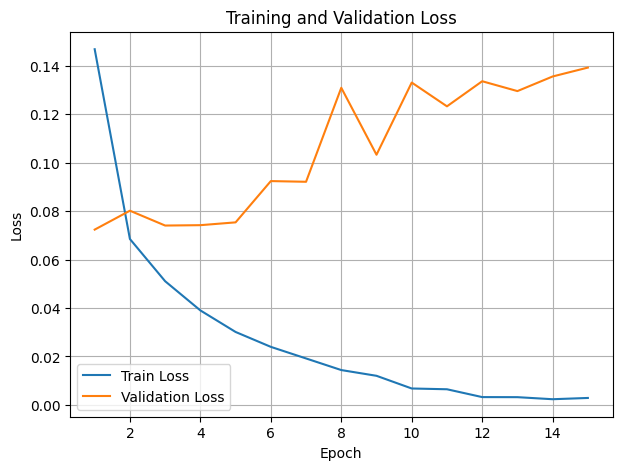

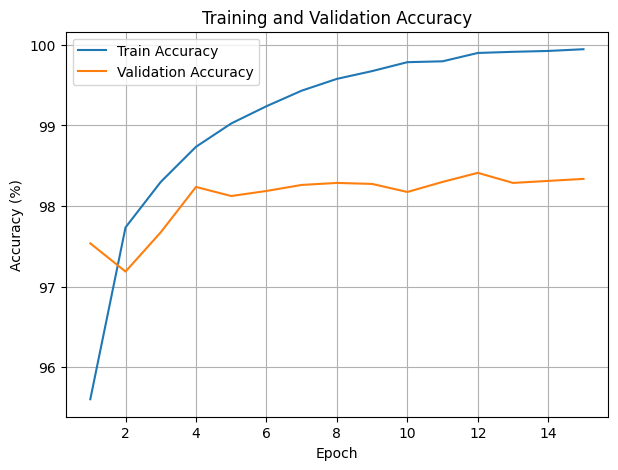

In [26]:
epochs_ran = range(
    1,
    len(history["train_loss"]) + 1
)


# Loss
plt.figure(figsize=(7, 5))

plt.plot(
    epochs_ran,
    history["train_loss"],
    label="Train Loss"
)

plt.plot(
    epochs_ran,
    history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title(
    "Training and Validation Loss"
)

plt.legend()

plt.grid(True)

plt.show()


# Accuracy
plt.figure(figsize=(7, 5))

plt.plot(
    epochs_ran,
    np.array(
        history["train_acc"]
    ) * 100,
    label="Train Accuracy"
)

plt.plot(
    epochs_ran,
    np.array(
        history["val_acc"]
    ) * 100,
    label="Validation Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title(
    "Training and Validation Accuracy"
)

plt.legend()

plt.grid(True)

plt.show()

In [27]:
@torch.no_grad()
def get_predictions(
    model,
    loader,
    device
):

    model.eval()

    all_labels = []

    all_preds = []

    all_probs = []


    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )


        outputs = model(images)


        probs = torch.softmax(
            outputs,
            dim=1
        )


        preds = torch.argmax(
            probs,
            dim=1
        )


        all_labels.extend(
            labels.cpu().numpy()
        )

        all_preds.extend(
            preds.cpu().numpy()
        )

        all_probs.append(
            probs.cpu().numpy()
        )


    return (

        np.array(all_labels),

        np.array(all_preds),

        np.concatenate(
            all_probs,
            axis=0
        )
    )


test_labels, test_preds, probs = get_predictions(

    model,

    test_loader,

    device
)

In [28]:
accuracy = accuracy_score(
    test_labels,
    test_preds
)


precision = precision_score(

    test_labels,

    test_preds,

    pos_label=CRACK_IDX,

    zero_division=0
)


recall = recall_score(

    test_labels,

    test_preds,

    pos_label=CRACK_IDX,

    zero_division=0
)


f1 = f1_score(

    test_labels,

    test_preds,

    pos_label=CRACK_IDX,

    zero_division=0
)


# Probability belonging to CRACK
crack_probs = probs[:, CRACK_IDX]


# Convert labels:
# crack = 1
# no_crack = 0

binary_labels = (
    test_labels == CRACK_IDX
).astype(int)


roc_auc = roc_auc_score(

    binary_labels,

    crack_probs
)


brier = brier_score_loss(

    binary_labels,

    crack_probs
)


print("========== TEST RESULTS ==========")

print(
    f"Accuracy : "
    f"{accuracy:.4f} "
    f"({accuracy*100:.2f}%)"
)

print(
    f"Precision: "
    f"{precision:.4f} "
    f"({precision*100:.2f}%)"
)

print(
    f"Recall   : "
    f"{recall:.4f} "
    f"({recall*100:.2f}%)"
)

print(
    f"F1 Score : "
    f"{f1:.4f} "
    f"({f1*100:.2f}%)"
)

print(
    f"ROC-AUC  : "
    f"{roc_auc:.4f}"
)

print(
    f"Brier    : "
    f"{brier:.4f}"
)

========== TEST RESULTS ==========
Accuracy : 0.9850 (98.50%)
Precision: 0.9860 (98.60%)
Recall   : 0.9840 (98.40%)
F1 Score : 0.9850 (98.50%)
ROC-AUC  : 0.9974
Brier    : 0.0128


In [29]:
print(
    classification_report(

        test_labels,

        test_preds,

        labels=[
            NO_CRACK_IDX,
            CRACK_IDX
        ],

        target_names=[
            "No Crack",
            "Crack"
        ],

        zero_division=0
    )
)

              precision    recall  f1-score   support

    No Crack       0.98      0.99      0.99      2000
       Crack       0.99      0.98      0.98      2000

    accuracy                           0.98      4000
   macro avg       0.99      0.98      0.98      4000
weighted avg       0.99      0.98      0.98      4000



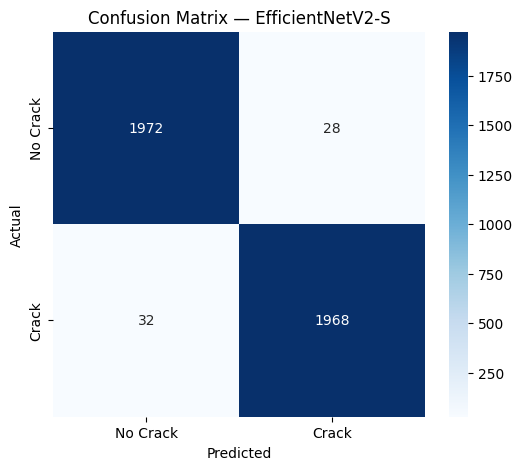

True Negative : 1972
False Positive: 28
False Negative: 32
True Positive : 1968
Total errors  : 60


In [36]:
cm = confusion_matrix(

    test_labels,

    test_preds,

    labels=[
        NO_CRACK_IDX,
        CRACK_IDX
    ]
)


plt.figure(figsize=(6, 5))


sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",   # 👈 BLUE CONFUSION MATRIX

    xticklabels=[
        "No Crack",
        "Crack"
    ],

    yticklabels=[
        "No Crack",
        "Crack"
    ]
)


plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.title(
    "Confusion Matrix — EfficientNetV2-S"
)

plt.show()


tn, fp, fn, tp = cm.ravel()


print("True Negative :", tn)

print("False Positive:", fp)

print("False Negative:", fn)

print("True Positive :", tp)

print("Total errors  :", fp + fn)

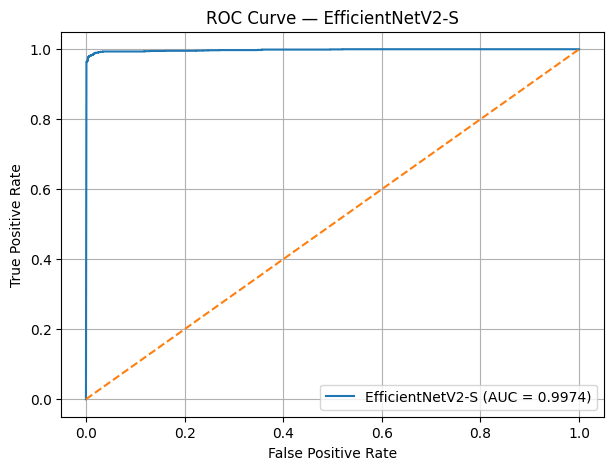

In [31]:
fpr, tpr, thresholds = roc_curve(

    binary_labels,

    crack_probs
)


plt.figure(figsize=(7, 5))


plt.plot(

    fpr,

    tpr,

    label=(
        f"EfficientNetV2-S "
        f"(AUC = {roc_auc:.4f})"
    )
)


plt.plot(

    [0, 1],

    [0, 1],

    linestyle="--"
)


plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "ROC Curve — EfficientNetV2-S"
)

plt.legend()

plt.grid(True)

plt.show()

In [32]:
# Warm-up
with torch.no_grad():

    for images, _ in list(test_loader)[:2]:

        images = images.to(device)

        _ = model(images)


if torch.cuda.is_available():

    torch.cuda.synchronize()


start = time.time()

num_images = 0


with torch.no_grad():

    for images, _ in test_loader:

        images = images.to(device)

        _ = model(images)

        num_images += images.size(0)


if torch.cuda.is_available():

    torch.cuda.synchronize()


inference_time = (
    time.time() - start
)


avg_inference_time = (
    inference_time / num_images
)


print(
    f"Total inference time: "
    f"{inference_time:.4f} seconds"
)

print(
    f"Images: {num_images}"
)

print(
    f"Average inference time: "
    f"{avg_inference_time:.6f} sec/image"
)

Total inference time: 11.6260 seconds
Images: 4000
Average inference time: 0.002906 sec/image


In [33]:
test_samples = test_ds.samples


misclassified = []


for i, (
    true_label,
    pred_label
) in enumerate(
    zip(
        test_labels,
        test_preds
    )
):

    if true_label != pred_label:

        misclassified.append({

            "index": i,

            "path":
                test_samples[i][0],

            "actual":
                test_ds.classes[
                    true_label
                ],

            "predicted":
                test_ds.classes[
                    pred_label
                ],

            "confidence":
                float(
                    probs[
                        i,
                        pred_label
                    ]
                )
        })


misclassified_df = pd.DataFrame(
    misclassified
)


print(
    "Total test images:",
    len(test_ds)
)

print(
    "Misclassified:",
    len(misclassified_df)
)

print(
    f"Error rate: "
    f"{len(misclassified_df) / len(test_ds) * 100:.2f}%"
)


display(
    misclassified_df.head(20)
)

Total test images: 4000
Misclassified: 60
Error rate: 1.50%


,index,path,actual,predicted,confidence
0,69,C:\Users\Students\Desktop\Crack classification...,crack,no_crack,1.000000
1,106,C:\Users\Students\Desktop\Crack classification...,crack,no_crack,0.999995
2,159,C:\Users\Students\Desktop\Crack classification...,crack,no_crack,0.994152
3,184,C:\Users\Students\Desktop\Crack classification...,crack,no_crack,0.978024
4,216,C:\Users\Students\Desktop\Crack classification...,crack,no_crack,1.000000
5,219,C:\Users\Students\Desktop\Crack classification...,crack,no_crack,0.916979
6,277,C:\Users\Students\Desktop\Crack classification...,crack,no_crack,0.841827
7,296,C:\Users\Students\Desktop\Crack classification...,crack,no_crack,1.000000
8,297,C:\Users\Students\Desktop\Crack classification...,crack,no_crack,1.000000
9,345,C:\Users\Students\Desktop\Crack classification...,crack,no_crack,1.000000


Brier score: 0.0128


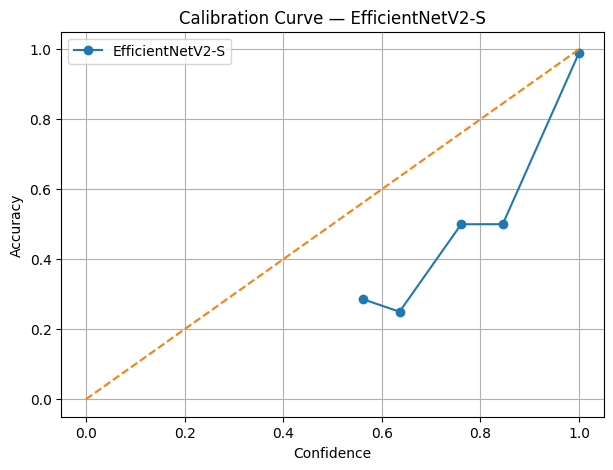

In [34]:
print(
    f"Brier score: {brier:.4f}"
)


plt.figure(figsize=(7, 5))


confidence = np.max(
    probs,
    axis=1
)


correct = (
    test_preds == test_labels
).astype(int)


bins = np.linspace(
    0.0,
    1.0,
    11
)


bin_acc = []

bin_conf = []


for lower, upper in zip(
    bins[:-1],
    bins[1:]
):

    if upper == 1.0:

        mask = (
            (confidence >= lower)
            &
            (confidence <= upper)
        )

    else:

        mask = (
            (confidence >= lower)
            &
            (confidence < upper)
        )


    if mask.sum() > 0:

        bin_acc.append(
            correct[mask].mean()
        )

        bin_conf.append(
            confidence[mask].mean()
        )


plt.plot(

    bin_conf,

    bin_acc,

    marker="o",

    label="EfficientNetV2-S"
)


plt.plot(

    [0, 1],

    [0, 1],

    linestyle="--"
)


plt.xlabel("Confidence")

plt.ylabel("Accuracy")

plt.title(
    "Calibration Curve — EfficientNetV2-S"
)

plt.legend()

plt.grid(True)

plt.show()

In [35]:
results = {

    "model":
        MODEL_KEY,

    "timm_name":
        TIMM_NAME,

    "image_size":
        IMG_SIZE,

    "batch_size":
        BATCH_SIZE,

    "epochs":
        EPOCHS,

    "learning_rate":
        LR,

    "weight_decay":
        WEIGHT_DECAY,

    "optimizer":
        "AdamW",

    "scheduler":
        "CosineAnnealingLR",

    "loss":
        "CrossEntropyLoss",

    "patience":
        PATIENCE,

    "gradient_clipping":
        GRAD_CLIP_NORM,

    "amp":
        USE_AMP,

    "seed":
        SEED,

    "best_val_accuracy":
        float(best_val_acc),

    "test_accuracy":
        float(accuracy),

    "test_precision":
        float(precision),

    "test_recall":
        float(recall),

    "test_f1":
        float(f1),

    "test_roc_auc":
        float(roc_auc),

    "brier_score":
        float(brier),

    "test_images":
        int(len(test_ds)),

    "misclassified":
        int(len(misclassified_df)),

    "false_positive":
        int(fp),

    "false_negative":
        int(fn),

    "total_parameters":
        int(total_params),

    "training_time_seconds":
        float(training_time),

    "average_inference_seconds_per_image":
        float(avg_inference_time)
}


results_path = (
    OUTPUT_DIR /
    "efficientnet_v2_s_results.json"
)


with open(
    results_path,
    "w"
) as f:

    json.dump(
        results,
        f,
        indent=4
    )


print(
    "Results saved to:"
)

print(results_path)


print("\n===== FINAL SUMMARY =====")

for key, value in results.items():

    print(
        f"{key}: {value}"
    )

Results saved to:
C:\Users\Students\Desktop\Crack classification(Indhu)\Output\efficientnet_v2_s_results.json

===== FINAL SUMMARY =====
model: efficientnet_v2_s
timm_name: tf_efficientnetv2_s.in1k
image_size: 224
batch_size: 32
epochs: 15
learning_rate: 0.0001
weight_decay: 0.0001
optimizer: AdamW
scheduler: CosineAnnealingLR
loss: CrossEntropyLoss
patience: 5
gradient_clipping: 1.0
amp: False
seed: 42
best_val_accuracy: 0.984125
test_accuracy: 0.985
test_precision: 0.9859719438877755
test_recall: 0.984
test_f1: 0.984984984984985
test_roc_auc: 0.99741875
brier_score: 0.01281702099229544
test_images: 4000
misclassified: 60
false_positive: 28
false_negative: 32
total_parameters: 20180050
training_time_seconds: 3331.737143754959
average_inference_seconds_per_image: 0.0029064932465553282


In [40]:
## Failure case analysis (display image)

# Get indices of misclassified images
misclassified_indices = np.where(
    test_labels != test_preds
)[0]

print(
    "Total misclassified images:",
    len(misclassified_indices)
)

Total misclassified images: 60


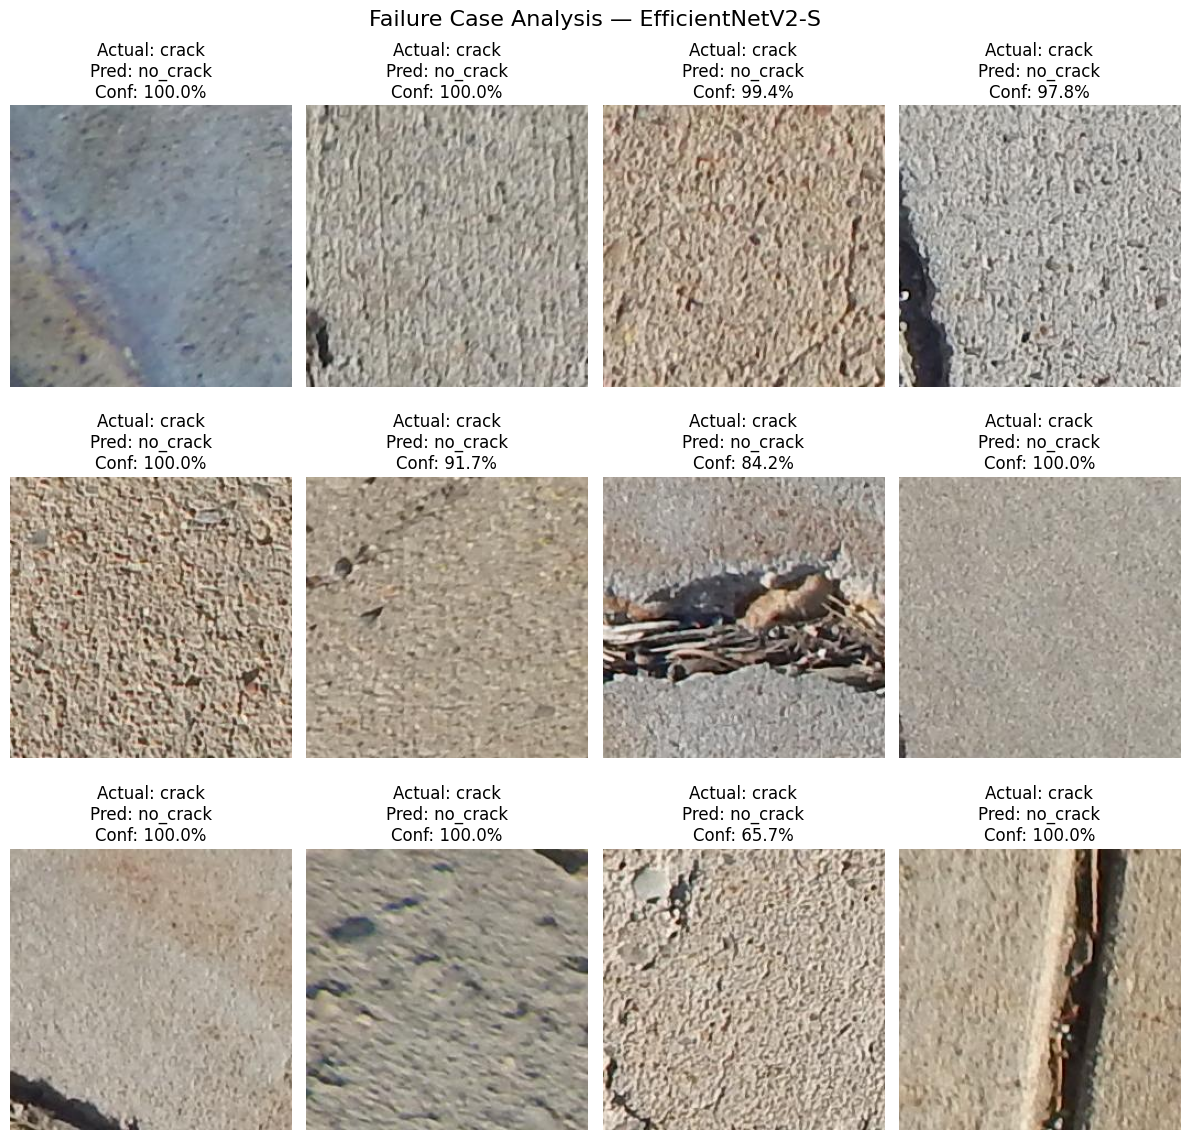

In [41]:
# Number of failure cases to display
NUM_FAILURES = min(
    12,
    len(misclassified_indices)
)


plt.figure(
    figsize=(12, 12)
)


for plot_idx, data_idx in enumerate(
    misclassified_indices[:NUM_FAILURES]
):

    # Get original image path
    image_path = test_ds.samples[data_idx][0]

    # Open image
    image = Image.open(
        image_path
    ).convert("RGB")

    # Get actual and predicted labels
    actual_label = test_ds.classes[
        test_labels[data_idx]
    ]

    predicted_label = test_ds.classes[
        test_preds[data_idx]
    ]

    # Prediction confidence
    confidence_value = probs[
        data_idx,
        test_preds[data_idx]
    ] * 100


    plt.subplot(
        3,
        4,
        plot_idx + 1
    )

    plt.imshow(image)

    plt.axis("off")

    plt.title(
        f"Actual: {actual_label}\n"
        f"Pred: {predicted_label}\n"
        f"Conf: {confidence_value:.1f}%"
    )


plt.suptitle(
    "Failure Case Analysis — EfficientNetV2-S",
    fontsize=16
)

plt.tight_layout()

plt.show()

In [42]:
# False negatives:
# Actual = Crack
# Predicted = No Crack

false_negative_indices = np.where(
    (test_labels == CRACK_IDX) &
    (test_preds == NO_CRACK_IDX)
)[0]

print(
    "False Negative images:",
    len(false_negative_indices)
)

False Negative images: 32


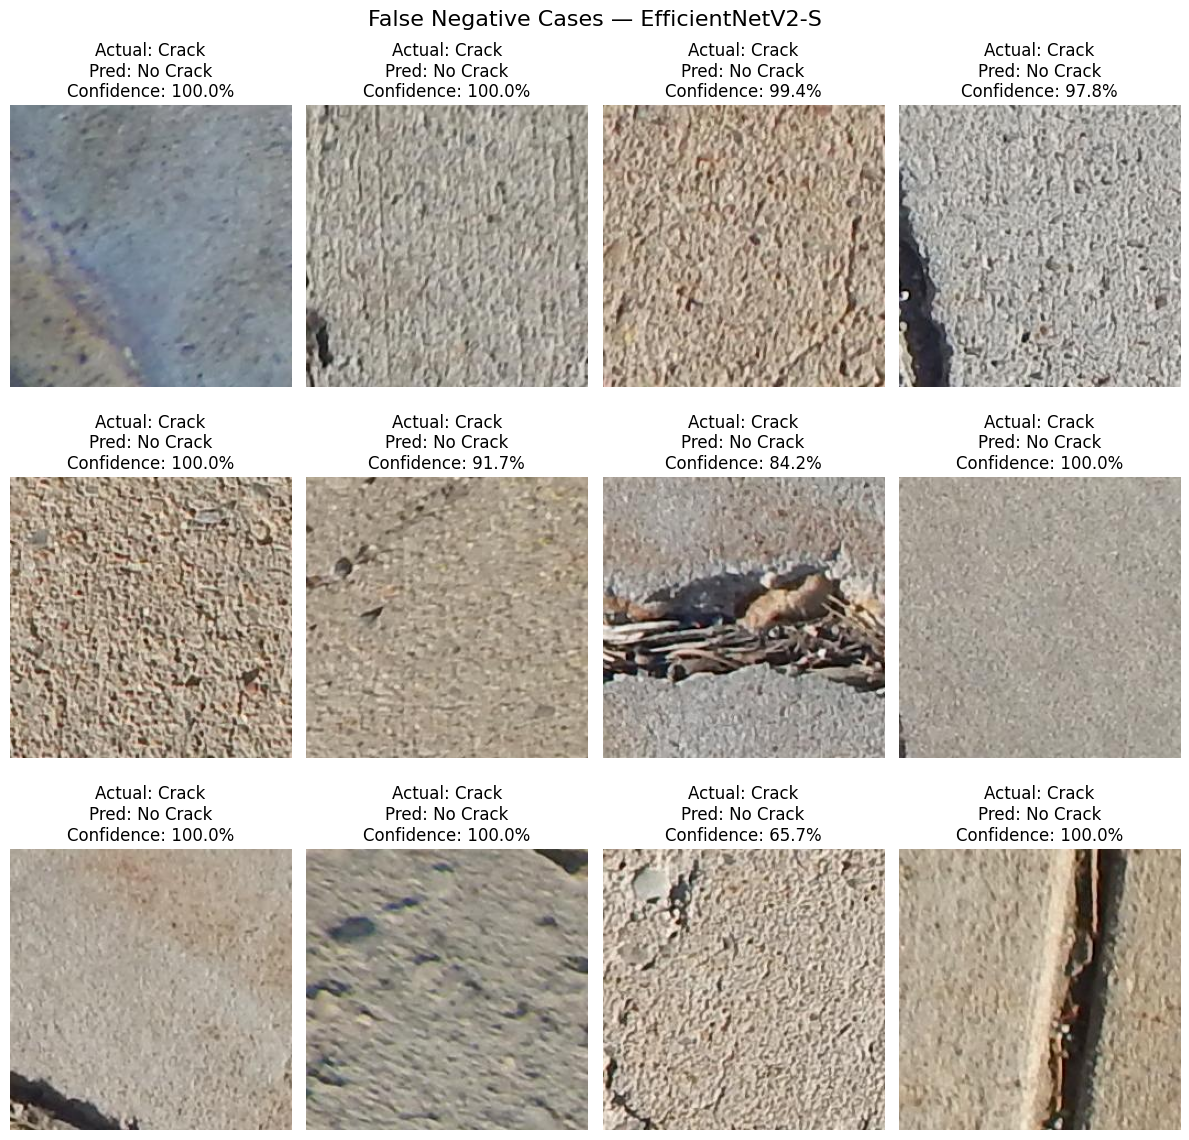

In [43]:
NUM_FN = min(
    12,
    len(false_negative_indices)
)

plt.figure(figsize=(12, 12))

for plot_idx, data_idx in enumerate(
    false_negative_indices[:NUM_FN]
):

    image_path = test_ds.samples[data_idx][0]

    image = Image.open(
        image_path
    ).convert("RGB")

    confidence_value = (
        probs[data_idx, NO_CRACK_IDX] * 100
    )

    plt.subplot(
        3,
        4,
        plot_idx + 1
    )

    plt.imshow(image)

    plt.axis("off")

    plt.title(
        f"Actual: Crack\n"
        f"Pred: No Crack\n"
        f"Confidence: {confidence_value:.1f}%"
    )


plt.suptitle(
    "False Negative Cases — EfficientNetV2-S",
    fontsize=16
)

plt.tight_layout()

plt.show()

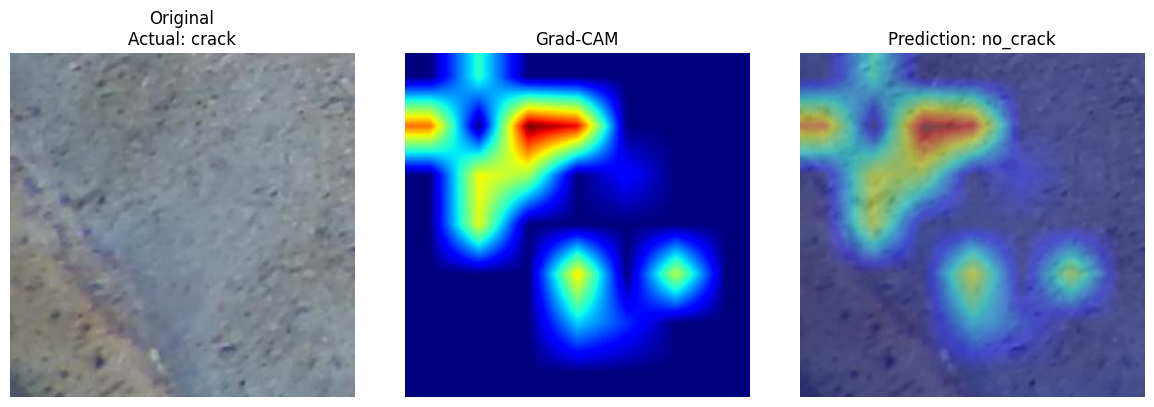

In [48]:
if len(false_negative_indices) > 0:

    first_fn = false_negative_indices[0]

    show_gradcam(
        data_idx=first_fn,
        gradcam=gradcam
    )

else:

    print(
        "No false-negative cases found."
    )